# Figure 5 — Genetics → function: SETBP1 convergent evidence chain
**A** coloc PP_H4 top candidates. **B** AG DNase empirical-null landscape
(observed credible-set variants vs 560 matched nulls; SETBP1 highlighted).
**C** AG empirical q summary for named candidates.
Data: `j45` matrix, `ag2_14_empirical_null_{DNASE,RNA_SEQ}.csv`,
`l16_full_allpairs_coloc_and_susie.csv`.

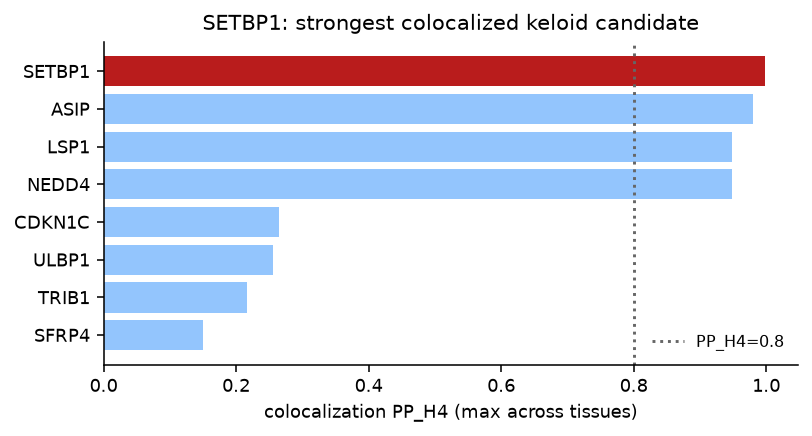

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RES = os.path.join("..", "..", "results")
FIG = os.path.join("..", "..", "figures")
os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"figure.dpi": 140, "savefig.dpi": 300,
                     "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False})
MODELS = ["lw", "svd20", "moppca5", "nn10", "nn50"]
MODEL_LABELS = {"lw": "LW shrinkage", "svd20": "SVD-20",
                "moppca5": "moPPCA-5", "nn10": "nn10",
                "nn50": "nn50"}
CONTEXTS = [
    ("K562 essential", "j22_k562_foldfrozen_centroid.csv"),
    ("K562 GWPS", "j22_k562_gwps_foldfrozen_centroid.csv"),
    ("Norman", "j49_norman_foldfrozen.csv"),
    ("RPE1", "j49_rpe1_foldfrozen.csv"),
    ("sci-Plex3", "j49_sciplex3.csv"),
    ("Frangieh", "j78_frangieh_merged.csv"),
    ("Tian CRISPRi", "j78_tian2021i_merged.csv"),
    ("RPE1 E150", "j78_rpe1e150_merged.csv"),
    ("Tahoe-100M", "j78_tahoe_merged.csv"),
]
def load_ctx(name, fname):
    df = pd.read_csv(os.path.join(RES, fname))
    df["context"] = name
    return df

ev = pd.read_csv(os.path.join(RES, "j45_candidate_evidence_matrix.csv"))
top = ev.dropna(subset=["coloc_PP_H4_max"]).nlargest(8, "coloc_PP_H4_max")
fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.barh(top.gene[::-1], top.coloc_PP_H4_max[::-1],
        color=["#b91c1c" if g == "SETBP1" else "#93c5fd" for g in top.gene[::-1]])
ax.axvline(0.8, color="0.4", ls=":", label="PP_H4=0.8")
ax.set_xlabel("colocalization PP_H4 (max across tissues)")
ax.set_title("SETBP1: strongest colocalized keloid candidate")
ax.legend(frameon=False, fontsize=8)
fig.savefig(os.path.join(FIG, "fig5a_coloc_pph4.png"), bbox_inches="tight")
plt.show()



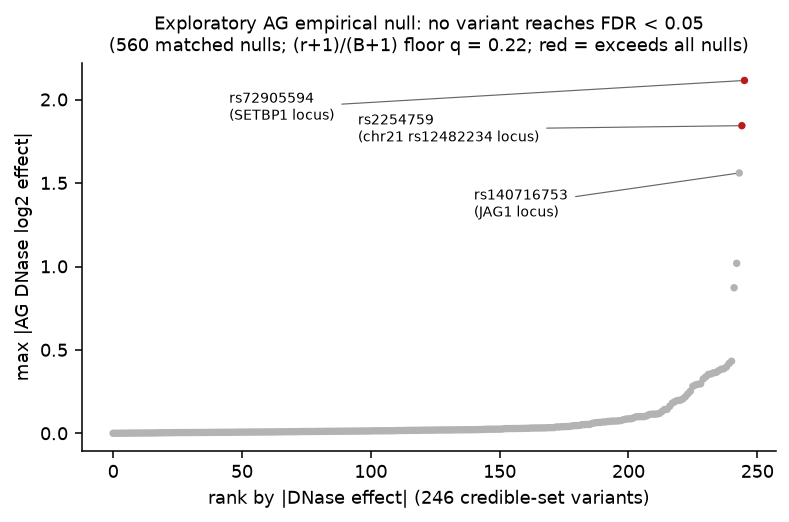

In [2]:
# ---- Panel B: AG DNase empirical null ----
dn = pd.read_csv(os.path.join(RES, "ag2_14_empirical_null_DNASE.csv"))
fig, ax = plt.subplots(figsize=(6.4, 3.6))
order = dn.sort_values("maxabs").reset_index(drop=True)
ax.scatter(order.index, order.maxabs, s=8,
           c=["#b91c1c" if r == 0 else "0.7" for r in order.r],
           label="credible-set variants")
named = {"rs72905594": "SETBP1 locus",
         "rs2254759": "chr21 rs12482234 locus",
         "rs140716753": "JAG1 locus"}
# staggered leader-line labels in the empty left region; no overlap
label_xy = {"rs72905594": (45, 1.88), "rs2254759": (95, 1.75),
            "rs140716753": (140, 1.30)}
for _, r in dn[dn.rsid.isin(named)].iterrows():
    i = order.index[order.rsid == r.rsid][0]
    lbl = r.rsid + chr(10) + "(" + named[r.rsid] + ")"
    ax.annotate(lbl, (i, r.maxabs), xytext=label_xy[r.rsid], fontsize=7,
                arrowprops=dict(arrowstyle="-", lw=0.6, color="0.4"))
ax.set_xlabel("rank by |DNase effect| (246 credible-set variants)")
ax.set_ylabel("max |AG DNase log2 effect|")
ax.set_title("Exploratory AG empirical null: no variant reaches FDR < 0.05" + chr(10) +
             "(560 matched nulls; (r+1)/(B+1) floor q = 0.22; red = exceeds all nulls)", fontsize=9)
fig.savefig(os.path.join(FIG, "fig5b_ag2_null.png"), bbox_inches="tight", dpi=300)
plt.show()


In [3]:

# ---- Panel C: q-value summary for named candidates ----
rn = pd.read_csv(os.path.join(RES, "ag2_14_empirical_null_RNA_SEQ.csv"))
m = dn.merge(rn, on="rsid", suffixes=("_dn", "_rna"))
ev_map = ev[["coloc_PP_H4_max"]]
print(m[m.q_emp_dn < 0.2][["rsid","maxabs_dn","q_emp_dn","maxabs_rna","q_emp_rna"]]
        .sort_values("q_emp_dn"))


Empty DataFrame
Columns: [rsid, maxabs_dn, q_emp_dn, maxabs_rna, q_emp_rna]
Index: []
